# Where should this portfolio live? Taxable account, TFSA or RRSP

The same stock-picking rule earns the same pre-tax return wherever you hold it. What changes is the tax: in a **taxable** account you pay tax on dividends and on gains as they are realized; in a **TFSA** you pay none, but foreign dividends are still taxed at the source; in an **RRSP** nothing is taxed while the money stays in, the US tax on US dividends is waived, and the whole balance is taxed as income when you take it out.

This notebook runs one operation, `lab.account_compare(...)`, that puts **the same portfolio and the passive index in each account** and shows the after-tax growth, the tax drag, and what happens to foreign withholding. It does not choose a rule for you and it is not tax advice.

What you will see, in order:

1. a Globe and Mail dividend screen on the synthetic Canadian market (Canadian names, so no foreign withholding);
2. two screens on the bundled S&P 500 sample (US names, so the foreign treatment shows up);
3. the withholding treatment matrix: what each kind of holding does in each account;
4. how to read it, and what it leaves out.

Settings used throughout: the Canadian model for **Alberta**, other income of **$90,000** a year (so the portfolio's income is taxed on top of that bracket), and an RRSP withdrawal taxed at a flat **30%**. Run all cells; about 20 seconds. Nothing is written to disk and nothing leaves your machine.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import screenlab
except ImportError:                       # running from a git checkout without installing the package
    sys.path.insert(0, str(Path.cwd().parent.parent))
    import screenlab
from screenlab import Lab
from screenlab.taxes import CanadianTax, TaxConfig
from screenlab.ops.account_compare import treatment
from screenlab.research.montecarlo_sp500 import INK, INK2, SURFACE, GRID, _style

# the shared tax settings: only `account` changes from one run to the next
TAX = TaxConfig(model=CanadianTax("AB", other_income=90_000), account="taxable", rrsp_withdrawal_rate=0.30)
BLUE, GREY = "#0072B2", "#6B6B6B"
ACCOUNTS = ["taxable", "tfsa", "rrsp"]
%matplotlib inline
plt.rcParams["figure.dpi"] = 80
_style()

## 1. A dividend screen on Canadian names

`stable_dividend` is one of the Globe and Mail portfolios (it holds companies that pay and keep paying dividends). The synthetic market is a made-up Canadian market so that this notebook runs offline; the numbers show how the machinery behaves, they are not a forecast. Rebalanced once a year.

In [2]:
lab = Lab.synthetic(freq="ME", n_stocks=150, years=12, seed=3)
rep = lab.account_compare(["stable_dividend"], tax=TAX, rebalance_months=12)
print(rep.data_card.line())

Data: synthetic, 2000-01-31..2011-12-31, 150 names, benchmark SYN_CAPWT (total_return), PIT yes, delisted yes (33), survivorship -2.4%/yr


The table has one row for the portfolio and one for the passive index in each account. Columns: **CAGR** is the growth per year before tax (the same in every account); **AfterTaxCAGR** is after tax; **TaxDrag/yr** is the difference; **AfterTaxExcess/yr** is the portfolio against the index *in the same account*; **WH...** is foreign withholding as a share of your wealth per year (lost, credited back through the foreign tax credit, or exempt); the dollar columns are the tax paid over the whole run on dividends, on gains and at the RRSP withdrawal; **Rank** orders the accounts by after-tax growth for that row and **GapToNext** is the lead over the account ranked just below.

In [3]:
def show(rep):
    t = rep.table.drop(columns=["name", "kind", "account", "TaxDeferred/yr"])
    pct = ["CAGR", "AfterTaxCAGR", "TaxDrag/yr", "AfterTaxExcess/yr", "WHLost/yr", "WHCredited/yr", "WHExempt/yr", "GapToNext"]
    fmt = {c: "{:.2%}" for c in pct}
    fmt.update({"DivTax$": "{:,.0f}", "GainTax$": "{:,.0f}", "WithdrawalTax$": "{:,.0f}", "TaxPaid$": "{:,.0f}", "Rank": "{:.0f}"})
    display(t.style.format(fmt, na_rep="-"))
    for name, b in rep.best.items():
        if b and b["next"]:
            print(f"best account for {name}: {b['account']} ({100 * b['gap']:+.2f} points a year over {b['next']})")

show(rep)

,CAGR,AfterTaxCAGR,TaxDrag/yr,AfterTaxExcess/yr,WHLost/yr,WHCredited/yr,WHExempt/yr,DivTax$,GainTax$,WithdrawalTax$,TaxPaid$,Rank,GapToNext
SYN_CAPWT | taxable,12.22%,12.03%,0.20%,-,0.00%,0.00%,0.00%,"4,568",0,0,"4,568",2,3.44%
SYN_CAPWT | tfsa,12.22%,12.22%,0.00%,-,0.00%,0.00%,0.00%,0,0,0,0,1,0.20%
SYN_CAPWT | rrsp,12.22%,8.59%,3.63%,-,0.00%,0.00%,0.00%,0,0,"104,688","104,688",3,-
stable_dividend | taxable,7.37%,6.55%,0.82%,-5.48%,0.00%,0.00%,0.00%,"5,175","13,559",0,"13,523",2,2.65%
stable_dividend | tfsa,7.37%,7.37%,0.00%,-4.86%,0.00%,0.00%,0.00%,0,0,0,0,1,0.82%
stable_dividend | rrsp,7.37%,3.89%,3.48%,-4.70%,0.00%,0.00%,0.00%,0,0,"64,828","64,828",3,-


best account for SYN_CAPWT: tfsa (+0.20 points a year over taxable)
best account for stable_dividend: tfsa (+0.82 points a year over taxable)


Notes the operation attaches to every result (read them; they are the part people skip):

In [4]:
for n in rep.notes:
    print("-", n)

- foreign: 0% of names, currencies CAD; withholding: taxable creditable (FTC), tfsa lost, rrsp exempt (US-listed); Canadian ETF on foreign stocks: lost in every account
- RRSP: deferred, taxed at withdrawal at 30.0% (assumed)
- years 2001-2011: no tax table, used 2025
- not modelled: contribution room (a TFSA / RRSP holds only what the room allows), the RRSP deduction refund on the way in, AMT, and the choice of which assets to put where beyond this portfolio; same pre-tax money in each account


### After-tax growth by account

Bars are the after-tax growth per year, the portfolio in blue and the equally taxed passive index in grey. The gap between the bars within one account is the **after-tax** excess return; the difference between accounts for one colour is what the wrapper is worth.

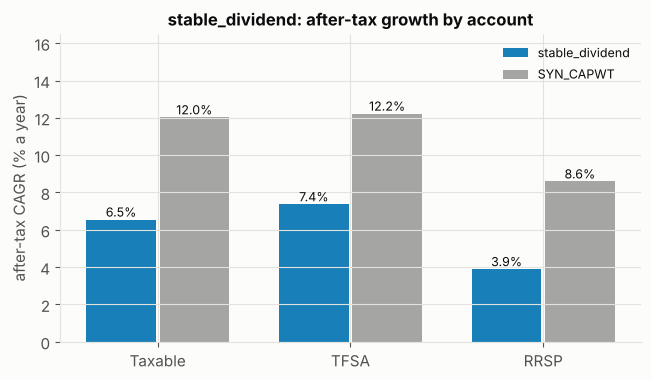

In [5]:
def chart_accounts(rep, name, ax=None, title=None):
    t = rep.table
    p, i = t[t["name"] == name].set_index("account"), t[t["kind"] == "index"].set_index("account")
    x = np.arange(len(rep.accounts)); w = 0.38
    fig, ax = (plt.subplots(figsize=(7.5, 4)) if ax is None else (ax.figure, ax))
    for off, d, col, lab_ in ((-w / 2, p, BLUE, name), (w / 2, i, GREY, rep.benchmark)):
        v = d.loc[list(rep.accounts), "AfterTaxCAGR"].to_numpy() * 100
        bars = ax.bar(x + off, v, w * 0.95, color=col, alpha=0.9 if col == BLUE else 0.6, label=lab_)
        for b, y in zip(bars, v):
            ax.text(b.get_x() + b.get_width() / 2, y, f"{y:.1f}%", ha="center", va="bottom", fontsize=9, color=INK)
    ax.set_xticks(x, [a.upper() if a != "taxable" else "Taxable" for a in rep.accounts])
    ax.set_ylabel("after-tax CAGR (% a year)"); ax.set_title(title or f"{name}: after-tax growth by account")
    ax.set_ylim(0, max(p["AfterTaxCAGR"].max(), i["AfterTaxCAGR"].max()) * 135); ax.legend(loc="upper right", fontsize=9)
    return fig

fig = chart_accounts(rep, "stable_dividend"); display(fig); plt.close(fig)

The foreign table shows what the portfolio actually holds. Here every name is Canadian, so there is no withholding to lose and the three treatments are the Canadian ones: the dividend tax credit in a taxable account, sheltered in the others.

In [6]:
display(rep.foreign.drop(columns="kind").style.format({"share": "{:.0%}", "rate": "{:.0%}"}).hide(axis="index"))

portfolio,class,country,share,rate,taxable,tfsa,rrsp
stable_dividend,Canadian stock,CA,100%,0%,gross-up and dividend tax credit,sheltered,sheltered; taxed at withdrawal


## 2. US names: where foreign withholding shows up

The bundled S&P 500 sample has 20 large US companies, 1990-2022, with prices only. Its prices already include dividends, so the sample has no dividend column; to make the tax stage see dividend income the next cell adds an **assumed 2% a year yield**, the same assumption the package already uses for the S&P 500 benchmark. That yield is an assumption, not data. The names are marked US-domiciled, so the dividends are foreign for a Canadian taxpayer.

In [7]:
from screenlab.dataset import BundledSP500Builder, Dataset
from screenlab.data import add_ratios
from screenlab.benchmarks import IndexBenchmark
from screenlab.realdata import bundled

ds = BundledSP500Builder().build()
q = ds.prices.resample("QE").last().dropna(how="all")                      # quarterly rows carrying the assumed 2% yield
rows = [dict(date=d, ticker=t, price=p, sector=bundled.SECTORS[t], market_cap=np.nan, dividend=0.02 * p)
        for d, r in q.iterrows() for t, p in r.dropna().items()]
ds2 = Dataset.from_frames(add_ratios(pd.DataFrame(rows)), ds.prices, ds.indices, name="sp500_bundled+2%div",
                          source="skfolio sample + assumed 2% yield", index_kinds={"SP500": "price"}, pit=None,
                          currency="USD", security_meta=ds.security_meta)
sp = Lab.from_dataset(ds2, screens=bundled.price_screens(5), benchmark=IndexBenchmark("SP500", dividend_yield=0.02))
rep_us = sp.account_compare(["momentum_12_1", "low_vol"], tax=TAX, rebalance_months=12)
print(rep_us.data_card.line()); print(rep_us.data_card.foreign_line())

Data: sp500_bundled+2%div, 1990-01-02..2022-12-28, 20 names, benchmark SP500 (approx_total_return: price index + assumed 2.0%/yr dividends), PIT n/a, delisted no, survivorship +7.9%/yr
foreign: 100% of names (US 100%), currencies USD; withholding: taxable creditable (FTC), tfsa lost, rrsp exempt (US-listed); Canadian ETF on foreign stocks: lost in every account
foreign: 100% of names (US 100%), currencies USD; withholding: taxable creditable (FTC), tfsa lost, rrsp exempt (US-listed); Canadian ETF on foreign stocks: lost in every account


In [8]:
show(rep_us)

,CAGR,AfterTaxCAGR,TaxDrag/yr,AfterTaxExcess/yr,WHLost/yr,WHCredited/yr,WHExempt/yr,DivTax$,GainTax$,WithdrawalTax$,TaxPaid$,Rank,GapToNext
SP500 +2.0% div (approx. TR) | taxable,9.92%,9.28%,0.64%,-,0.00%,0.30%,0.00%,"118,346",0,0,"118,346",2,0.58%
SP500 +2.0% div (approx. TR) | tfsa,9.92%,9.61%,0.31%,-,0.30%,0.00%,0.00%,"61,274",0,0,"61,274",1,0.33%
SP500 +2.0% div (approx. TR) | rrsp,9.92%,8.70%,1.22%,-,0.00%,0.00%,0.30%,0,0,"612,760","612,760",3,-
momentum_12_1 | taxable,21.20%,18.12%,3.08%,8.84%,0.00%,0.30%,0.00%,"1,057,996","3,677,739",0,"4,586,767",3,-
momentum_12_1 | tfsa,21.20%,20.87%,0.33%,11.26%,0.30%,0.00%,0.00%,"707,413",0,0,"707,413",1,1.01%
momentum_12_1 | rrsp,21.20%,19.85%,1.35%,11.15%,0.00%,0.00%,0.30%,0,0,"13,816,793","13,816,793",2,1.73%
low_vol | taxable,11.67%,10.13%,1.54%,0.85%,0.00%,0.31%,0.00%,"174,044","256,710",0,"408,201",3,-
low_vol | tfsa,11.67%,11.35%,0.32%,1.75%,0.31%,0.00%,0.00%,"106,626",0,0,"106,626",1,0.92%
low_vol | rrsp,11.67%,10.43%,1.24%,1.73%,0.00%,0.00%,0.31%,0,0,"1,014,188","1,014,188",2,0.30%


best account for SP500 +2.0% div (approx. TR): tfsa (+0.33 points a year over taxable)
best account for momentum_12_1: tfsa (+1.01 points a year over rrsp)
best account for low_vol: tfsa (+0.92 points a year over rrsp)


Look at the three withholding columns. The assumed 2% yield is withheld at 15% by the US, which is 0.30% of your wealth a year. In the **taxable** account that withholding is *credited* (the foreign tax credit gives it back against Canadian tax); in the **TFSA** it is simply *lost*; in the **RRSP** it is *exempt* (the Canada-US treaty waives it for an RRSP, but only for US dividends). That is why the TFSA, which looks free of tax, still pays a little on US stocks.

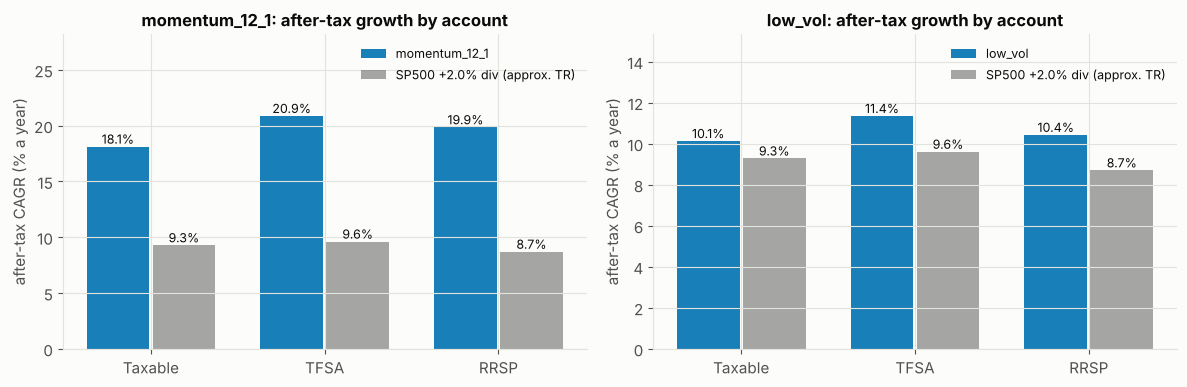

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, ["momentum_12_1", "low_vol"]):
    chart_accounts(rep_us, name, ax=ax)
fig.tight_layout(); display(fig); plt.close(fig)

In [10]:
for n in rep_us.notes:
    print("-", n)
display(rep_us.foreign.drop(columns="kind").style.format({"share": "{:.0%}", "rate": "{:.0%}"}).hide(axis="index"))

- passive index taxed with a foreign dividend share of 100% (the data card's share of foreign names); set `index_foreign_share` to change it
- foreign: 100% of names (US 100%), currencies USD; withholding: taxable creditable (FTC), tfsa lost, rrsp exempt (US-listed); Canadian ETF on foreign stocks: lost in every account
- RRSP: deferred, taxed at withdrawal at 30.0% (assumed)
- years 1991-2022: no tax table, used 2025
- CAD-basis warning: foreign gains taxed in portfolio currency; load an FX series for CAD basis
- not modelled: contribution room (a TFSA / RRSP holds only what the room allows), the RRSP deduction refund on the way in, AMT, and the choice of which assets to put where beyond this portfolio; same pre-tax money in each account


portfolio,class,country,share,rate,taxable,tfsa,rrsp
momentum_12_1,US stock (direct),US,100%,15%,"15% withheld, creditable (FTC)","15% withheld, LOST",EXEMPT (treaty)
low_vol,US stock (direct),US,100%,15%,"15% withheld, creditable (FTC)","15% withheld, LOST",EXEMPT (treaty)
SP500 +2.0% div (approx. TR) (assumed split),US stock (direct),US,100%,15%,"15% withheld, creditable (FTC)","15% withheld, LOST",EXEMPT (treaty)


## 3. The withholding matrix, for any holding

What a dividend does in each account depends on where the company is and how you own it. This is the matrix the tax stage uses (`docs/TAXES.md`, "Foreign holdings"), at the default 15% treaty rate.

In [11]:
classes = [("Canadian stock", "domestic", "CA"), ("US stock or US-listed ETF, held directly", "direct", "US"),
           ("UK stock, held directly", "direct", "GB"), ("Canadian-listed ETF that holds US stocks", "fund", "US")]
mx = pd.DataFrame([{"holding": n, **{a: treatment(k, c, 0.0 if k == "domestic" else 0.15)[a] for a in ACCOUNTS}}
                   for n, k, c in classes]).set_index("holding")
display(mx.rename(columns={"taxable": "Taxable", "tfsa": "TFSA", "rrsp": "RRSP"}).style.set_properties(**{"text-align": "left"}))

,Taxable,TFSA,RRSP
holding,,,
Canadian stock,gross-up and dividend tax credit,sheltered,sheltered; taxed at withdrawal
"US stock or US-listed ETF, held directly","15% withheld, creditable (FTC)","15% withheld, LOST",EXEMPT (treaty)
"UK stock, held directly","15% withheld, creditable (FTC)","15% withheld, LOST","15% withheld, LOST (exemption is US only)"
Canadian-listed ETF that holds US stocks,"15% withheld inside the fund, LOST; net taxed as foreign income","15% withheld inside the fund, LOST","15% withheld inside the fund, LOST"


## How to read this

* **Rank is by after-tax growth of the same money.** In these runs the TFSA ranks first: it pays no tax at the end, and its only cost is foreign withholding. The size of the lead is the number to look at: a portfolio that turns over a lot (many realized gains) or pays high dividends gains more from sheltering than a buy-and-hold index does.
* **The RRSP row depends on one assumption you supply: the tax rate at withdrawal.** Here 30% on the whole balance on the last day. Change `rrsp_withdrawal_rate` (or give `rrsp_withdrawal_income` to look the rate up) and the RRSP can move above or below the taxable account. Without a rate the operation says "RRSP withdrawals untaxed", shows the RRSP as if it were free, and leaves it out of the ranking.
* **Compare the portfolio with the index within an account.** `AfterTaxExcess/yr` is the portfolio against the equally taxed index. A screen can beat the index before tax and lose to it after tax in a taxable account, because it sells and pays dividends more than a buy-and-hold index.
* **Foreign names: the order is RRSP, then taxable, then TFSA** for US dividends, because the RRSP pays no withholding, a taxable account gets it back as a credit, and a TFSA does neither. For a Canadian-listed ETF that holds US stocks the withholding inside the fund is lost in every account.

## What this cannot tell you

* **Contribution room.** A TFSA or RRSP holds only what the room allows. The comparison puts all the money in each account in turn; in practice you fill one and overflow into the next.
* **The RRSP deduction refund.** The tax saved when you put money in is not modelled. It is what makes an RRSP attractive for someone in a high bracket now and a lower one later; here the RRSP is credited only with its tax-free growth and charged the tax at the end.
* **AMT and other interactions.** Alternative minimum tax, OAS clawback, and the effect of withdrawals on benefits are ignored. Gains in a US dollar are taxed in the portfolio currency unless an exchange-rate series is loaded (see the CAD-basis note).
* **The data.** The Canadian market here is synthetic; the S&P 500 sample is 20 survivors with an assumed 2% yield. The point is the comparison between accounts, not the level of any return.
* **Not tax advice.** The Alberta tables are the owner's reference numbers; check them against the CRA and Alberta sources for the year before relying on a figure.